In [1]:
!pip install -q ultralytics==8.4.207          # même version que requirements.txt ; torch CUDA de Kaggle conservé

import torch, ultralytics
print("ultralytics:", ultralytics.__version__) # attendu : 8.4.207
print("torch      :", torch.__version__)       # version CUDA fournie par Kaggle
print("CUDA       :", torch.cuda.is_available())
print("GPU        :", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
ultralytics: 8.4.207
torch      : 2.11.0+cu130
CUDA       : True
GPU        : Tesla T4


In [2]:
import os
from collections import Counter
from pathlib import Path

ROOT = Path("/kaggle/input")                   # Kaggle monte chaque dataset ajouté ici

# 1) Arborescence : pour chaque dossier, le nombre de fichiers par extension
for dirpath, dirnames, filenames in os.walk(ROOT):
    if filenames:                              # on n'affiche que les dossiers qui contiennent des fichiers
        exts = Counter(Path(f).suffix.lower() for f in filenames)
        print(f"{dirpath}  ->  {dict(exts)}")

# 2) Contenu de chaque fichier .yaml (il donne souvent les chemins et les noms des classes)
for y in ROOT.rglob("*.yaml"):
    print("\n" + "=" * 70 + f"\n{y}\n" + "=" * 70)
    print(y.read_text()[:2000])                # 2000 caractères suffisent pour un data.yaml

# 3) Exemple de label : les 5 premières lignes d'un .txt
txts = [t for t in ROOT.rglob("*.txt") if "label" in str(t).lower()]
if txts:
    print("\nExample label file:", txts[0])
    print(txts[0].read_text().splitlines()[:5])  # format YOLO attendu : "classe x_c y_c w h" (valeurs 0–1)
else:
    print("\nNo .txt label file found: the labels may use another format (XML, JSON...)")

/kaggle/input/datasets/pkdarabi/the-drug-name-detection-dataset  ->  {'.yaml': 1}
/kaggle/input/datasets/pkdarabi/the-drug-name-detection-dataset/test/images  ->  {'.jpg': 182}
/kaggle/input/datasets/pkdarabi/the-drug-name-detection-dataset/test/labels  ->  {'.txt': 182}
/kaggle/input/datasets/pkdarabi/the-drug-name-detection-dataset/train/images  ->  {'.jpg': 1276}
/kaggle/input/datasets/pkdarabi/the-drug-name-detection-dataset/train/labels  ->  {'.txt': 1276}
/kaggle/input/datasets/pkdarabi/the-drug-name-detection-dataset/valid/images  ->  {'.jpg': 365}
/kaggle/input/datasets/pkdarabi/the-drug-name-detection-dataset/valid/labels  ->  {'.txt': 365}

/kaggle/input/datasets/pkdarabi/the-drug-name-detection-dataset/data.yaml
train: ../train/images
val: ../valid/images
test: ../test/images

nc: 1
names: ['drug-name']

roboflow:
  workspace: kabul-university-evptq
  project: drug-name-detection
  version: 2
  license: CC BY 4.0
  url: https://universe.roboflow.com/kabul-university-evptq/dr

In [3]:
# ===== Cellule 3 : audit chiffré du dataset (lecture seule, aucune image modifiée) =====
import hashlib, json
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
from PIL import Image

DS = Path("/kaggle/input/datasets/pkdarabi/the-drug-name-detection-dataset")  # chemin vu dans la cellule 2
SPLITS = ["train", "valid", "test"]
audit = {}                                    # tout ce qu'on mesure, sauvé en JSON à la fin

orig_by_split = defaultdict(set)             # nom de la photo d'origine (avant ".rf.") -> pour détecter les fuites
md5_by_split = defaultdict(set)              # empreinte exacte des octets -> doublons identiques

for split in SPLITS:
    img_dir, lab_dir = DS / split / "images", DS / split / "labels"
    images = sorted(img_dir.glob("*.jpg"))
    sizes, ws, hs, areas, tall, per_img = Counter(), [], [], [], 0, []
    missing, empty, bad_coord, classes = 0, 0, 0, Counter()

    for img in images:
        orig_by_split[split].add(img.name.split(".rf.")[0])            # Roboflow : "<photo>_jpg.rf.<hash>.jpg"
        md5_by_split[split].add(hashlib.md5(img.read_bytes()).hexdigest())
        with Image.open(img) as im:                                    # lit seulement l'en-tête : rapide
            W, H = im.size
        sizes[(W, H)] += 1

        lab = lab_dir / (img.stem + ".txt")
        if not lab.exists():
            missing += 1; per_img.append(0); continue
        rows = [r.split() for r in lab.read_text().splitlines() if r.strip()]
        if not rows:
            empty += 1
        per_img.append(len(rows))
        for r in rows:
            c, x, y, w, h = int(r[0]), *map(float, r[1:5])             # format YOLO : classe x_c y_c w h (0–1)
            classes[c] += 1
            if not all(0 <= v <= 1 for v in (x, y, w, h)):
                bad_coord += 1
            ws.append(w); hs.append(h); areas.append(w * h)
            if h * H > w * W:                                          # plus haute que large EN PIXELS
                tall += 1

    n_boxes = len(areas)
    q = lambda a: [round(float(v), 4) for v in np.quantile(a, [0.05, 0.5, 0.95])] if a else None
    audit[split] = {
        "images": len(images), "labels_missing": missing, "labels_empty": empty,
        "boxes": n_boxes, "classes": dict(classes), "bad_coordinates": bad_coord,
        "boxes_per_image_max": max(per_img) if per_img else 0,
        "box_w_q05_q50_q95": q(ws), "box_h_q05_q50_q95": q(hs), "box_area_q05_q50_q95": q(areas),
        "boxes_area_below_1pct": int(sum(a < 0.01 for a in areas)),
        "boxes_taller_than_wide_px": tall,
        "top_image_sizes": [[f"{w}x{h}", n] for (w, h), n in sizes.most_common(5)],
    }

# Fuites entre splits : même photo d'origine, ou même fichier exact, dans deux splits
for a, b in [("train", "valid"), ("train", "test"), ("valid", "test")]:
    audit[f"leak_same_original_{a}_{b}"] = len(orig_by_split[a] & orig_by_split[b])
    audit[f"leak_identical_file_{a}_{b}"] = len(md5_by_split[a] & md5_by_split[b])
for s in SPLITS:
    audit[f"{s}_unique_originals"] = len(orig_by_split[s])            # < images => plusieurs versions augmentées

print(json.dumps(audit, indent=2))
Path("/kaggle/working/audit.json").write_text(json.dumps(audit, indent=2))   # gardé comme preuve


{
  "train": {
    "images": 1276,
    "labels_missing": 0,
    "labels_empty": 2,
    "boxes": 1277,
    "classes": {
      "0": 1277
    },
    "bad_coordinates": 0,
    "boxes_per_image_max": 2,
    "box_w_q05_q50_q95": [
      0.0399,
      0.2922,
      0.7665
    ],
    "box_h_q05_q50_q95": [
      0.025,
      0.1078,
      0.469
    ],
    "box_area_q05_q50_q95": [
      0.0035,
      0.0238,
      0.1824
    ],
    "boxes_area_below_1pct": 285,
    "boxes_taller_than_wide_px": 354,
    "top_image_sizes": [
      [
        "640x640",
        1276
      ]
    ]
  },
  "valid": {
    "images": 365,
    "labels_missing": 0,
    "labels_empty": 2,
    "boxes": 364,
    "classes": {
      "0": 364
    },
    "bad_coordinates": 0,
    "boxes_per_image_max": 2,
    "box_w_q05_q50_q95": [
      0.043,
      0.2957,
      0.6776
    ],
    "box_h_q05_q50_q95": [
      0.0242,
      0.1082,
      0.4982
    ],
    "box_area_q05_q50_q95": [
      0.0036,
      0.0231,
      0.1787
    ],


2057

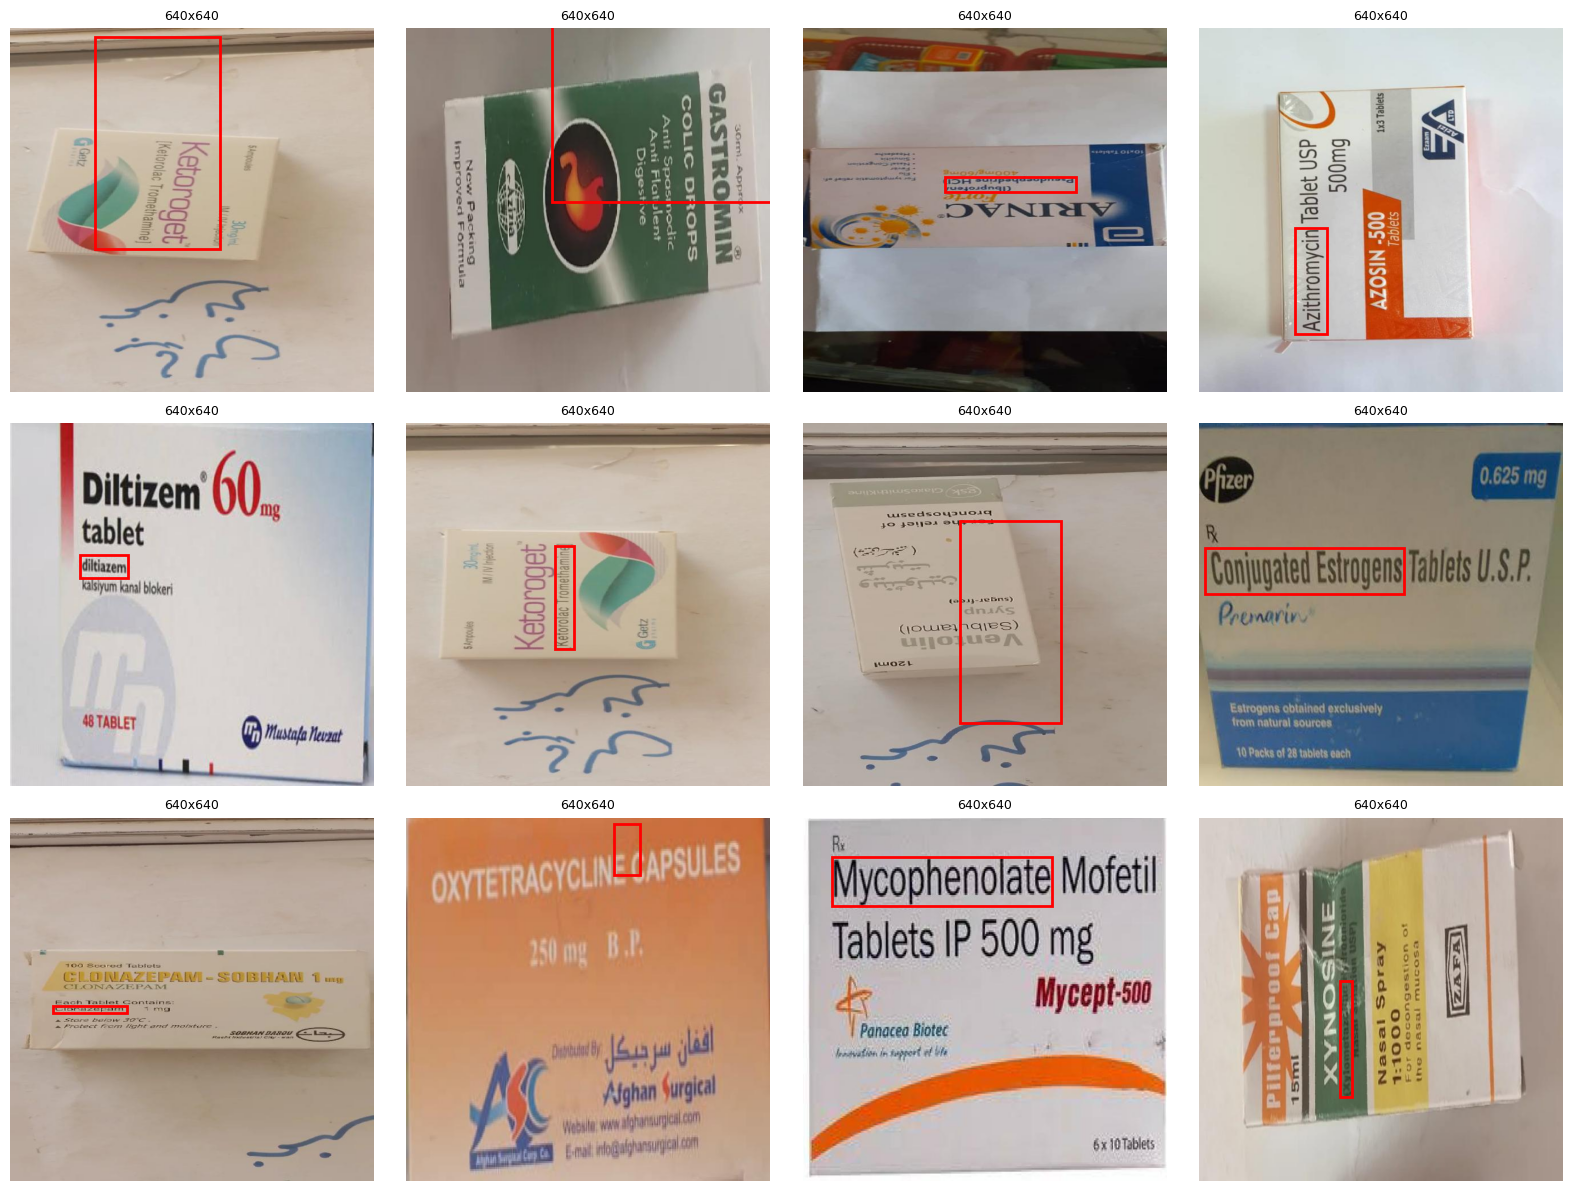

In [4]:
# ===== Cellule 4 : voir 12 images d'entraînement avec leurs boîtes =====
import random
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

random.seed(42)                                                     # même tirage à chaque exécution
imgs = random.sample(sorted((DS / "train" / "images").glob("*.jpg")), 12)
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
for ax, img in zip(axes.flat, imgs):
    im = Image.open(img); W, H = im.size
    ax.imshow(im); ax.set_title(f"{W}x{H}", fontsize=9); ax.axis("off")
    lab = DS / "train" / "labels" / (img.stem + ".txt")
    for r in lab.read_text().splitlines():
        _, x, y, w, h = map(float, r.split()[:5])
        # YOLO donne le centre normalisé -> coin haut-gauche en pixels pour matplotlib
        ax.add_patch(patches.Rectangle(((x - w / 2) * W, (y - h / 2) * H), w * W, h * H,
                                       fill=False, edgecolor="red", linewidth=2))
plt.tight_layout()
plt.savefig("/kaggle/working/train_grid.png", dpi=80)               # gardé pour le README
plt.show()


In [5]:
# ===== Cellule 5 : data.yaml + run A (défaut) + run B (adapté au texte) =====
import json, time
from pathlib import Path
import yaml
from ultralytics import YOLO

DS = Path("/kaggle/input/datasets/pkdarabi/the-drug-name-detection-dataset")
WORK = Path("/kaggle/working")

# 1) Notre propre data.yaml, avec des chemins ABSOLUS (celui du dataset utilise "../train", qui pointe au mauvais endroit)
#    L'audit a mesuré 0 fuite entre splits : on garde les splits tels quels (règle du protocole, section 6).
cfg = {"path": str(DS), "train": "train/images", "val": "valid/images", "test": "test/images",
       "nc": 1, "names": ["drug-name"]}
(WORK / "data.yaml").write_text(yaml.safe_dump(cfg))

# 2) Réglages communs aux deux runs : tous fixés dans PROTOCOL.md
COMMON = dict(
    data=str(WORK / "data.yaml"),
    epochs=50,            # nombre maximal de passages sur le train
    patience=10,          # early stopping : arrêt si la val ne progresse plus pendant 10 epochs
    imgsz=640,            # = taille native des images (audit : 100 % en 640x640)
    batch=16,             # tient dans les 16 Go du T4
    device=0,             # un seul GPU
    seed=42, deterministic=True,   # reproductible
    project=str(WORK / "runs"),
    exist_ok=True,        # si on relance, on écrase au lieu de créer A_default2, A_default3...
    plots=True,           # courbes et matrices sauvées (preuves pour le README)
)

RUNS = {
    "A_default": {},                                                # augmentation par défaut d'Ultralytics
    "B_text": {"fliplr": 0.0, "degrees": 5.0, "perspective": 0.0005},  # pas de miroir, petite rotation, perspective
}

minutes = {}
for name, extra in RUNS.items():
    t0 = time.time()
    YOLO("yolov8n.pt").train(name=name, **COMMON, **extra)         # repart de COCO à chaque run : runs indépendants
    minutes[name] = round((time.time() - t0) / 60, 1)              # durée MESURÉE
    print(f"\n### {name} trained in {minutes[name]} min\n")

(WORK / "train_minutes.json").write_text(json.dumps(minutes, indent=2))
print(minutes)


New https://pypi.org/project/ultralytics/8.4.208 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.207 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.9

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/50      2.51G      1.753      2.353      1.583         25        640: 100% ━━━━━━━━━━━━ 80/80 7.3it/s 11.0s0.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 12/12 4.7it/s 2.5s0.2s
                   all        365        364      0.208      0.231      0.143     0.0545

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/50      2.52G      1.809      2.346      1.643         23        640: 100% ━━━━━━━━━━━━ 80/80 7.4it/s 10.8s0.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 12/12 5.0it/s 2.4s0.2s
                   all        365        364      0.103      0.143     0.0443      0.015

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/50      2.52G      1.788      2.306      1.668         25        640: 100% ━━━━━━━━━━━━ 80/80 7.2it/s 11.1s0.3s
                 Class     Images  Inst

In [6]:
# ===== Cellule 6 : choisir A ou B sur la VAL (règle automatique), puis test Kaggle UNE seule fois =====
import json
from pathlib import Path
from ultralytics import YOLO

WORK = Path("/kaggle/working")
EVAL = dict(data=str(WORK / "data.yaml"), imgsz=640, batch=16, device=0, plots=False)

# 1) mAP@0.5 de chaque run sur la val, avec ses meilleurs poids (best.pt)
val = {}
for name in ["A_default", "B_text"]:
    m = YOLO(str(WORK / "runs" / name / "weights" / "best.pt")).val(split="val", **EVAL)
    val[name] = {"map50": round(float(m.box.map50), 4), "map50_95": round(float(m.box.map), 4)}
print("VAL:", val)

# 2) Règle du protocole : on garde le meilleur mAP@0.5 sur la val. Aucun choix à la main.
kept = max(val, key=lambda k: val[k]["map50"])
print("KEPT RUN:", kept)

# 3) Test Kaggle : UNE seule évaluation, seulement pour le run gardé
t = YOLO(str(WORK / "runs" / kept / "weights" / "best.pt")).val(split="test", **EVAL)
test = {"map50": round(float(t.box.map50), 4), "map50_95": round(float(t.box.map), 4),
        "precision": round(float(t.box.mp), 4), "recall": round(float(t.box.mr), 4)}
print("TEST (once):", test)

out = {"val": val, "kept_run": kept, "kaggle_test_once": test,
       "train_minutes": json.loads((WORK / "train_minutes.json").read_text())}
(WORK / "yolo_results.json").write_text(json.dumps(out, indent=2))
print(json.dumps(out, indent=2))


Ultralytics 8.4.207 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.4±0.0 ms, read: 49.0±16.2 MB/s, size: 30.2 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /kaggle/input/datasets/pkdarabi/the-drug-name-detection-dataset/valid/labels... 365 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 365/365 737.4it/s 0.5s0.1s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/pkdarabi/the-drug-name-detection-dataset/valid is not writable, cache not saved.
WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 44, len(boxes) = 364. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
                

In [7]:
# ===== Cellule 7 : correction de l'audit — certaines lignes de label sont des POLYGONES, pas des boîtes =====
# Format boîte    : classe x_c y_c w h            (5 valeurs)
# Format polygone : classe x1 y1 x2 y2 x3 y3 ...  (plus de 5 valeurs)
# La cellule 3 lisait toujours les 4 premières valeurs comme x_c y_c w h : faux pour les polygones.
# Ultralytics, lui, convertit chaque polygone en boîte englobante : l'ENTRAÎNEMENT était correct.
import json
from pathlib import Path
import numpy as np
from PIL import Image

DS = Path("/kaggle/input/datasets/pkdarabi/the-drug-name-detection-dataset")
fixed = {}
for split in ["train", "valid", "test"]:
    n_box, n_poly, areas, tall, total = 0, 0, [], 0, 0
    for lab in sorted((DS / split / "labels").glob("*.txt")):
        img = DS / split / "images" / (lab.stem + ".jpg")
        with Image.open(img) as im:
            W, H = im.size
        for r in lab.read_text().splitlines():
            v = r.split()
            if not v:
                continue
            nums = list(map(float, v[1:]))
            if len(nums) == 4:                               # vraie boîte YOLO
                n_box += 1
                w, h = nums[2], nums[3]
            else:                                            # polygone -> boîte englobante (comme Ultralytics)
                n_poly += 1
                xs, ys = nums[0::2], nums[1::2]
                w, h = max(xs) - min(xs), max(ys) - min(ys)
            total += 1
            areas.append(w * h)
            tall += int(h * H > w * W)                       # plus haute que large en pixels
    fixed[split] = {
        "rows": total, "box_rows": n_box, "polygon_rows": n_poly,
        "box_area_q05_q50_q95": [round(float(x), 4) for x in np.quantile(areas, [0.05, 0.5, 0.95])],
        "boxes_area_below_1pct": int(sum(a < 0.01 for a in areas)),
        "boxes_taller_than_wide_px": tall,
        "taller_than_wide_pct": round(100 * tall / total, 1),
    }
print(json.dumps(fixed, indent=2))
Path("/kaggle/working/audit_fixed.json").write_text(json.dumps(fixed, indent=2))


{
  "train": {
    "rows": 1277,
    "box_rows": 1095,
    "polygon_rows": 182,
    "box_area_q05_q50_q95": [
      0.0035,
      0.0217,
      0.1338
    ],
    "boxes_area_below_1pct": 295,
    "boxes_taller_than_wide_px": 270,
    "taller_than_wide_pct": 21.1
  },
  "valid": {
    "rows": 364,
    "box_rows": 320,
    "polygon_rows": 44,
    "box_area_q05_q50_q95": [
      0.0039,
      0.0203,
      0.1249
    ],
    "boxes_area_below_1pct": 87,
    "boxes_taller_than_wide_px": 74,
    "taller_than_wide_pct": 20.3
  },
  "test": {
    "rows": 182,
    "box_rows": 157,
    "polygon_rows": 25,
    "box_area_q05_q50_q95": [
      0.0041,
      0.0198,
      0.0988
    ],
    "boxes_area_below_1pct": 45,
    "boxes_taller_than_wide_px": 40,
    "taller_than_wide_pct": 22.0
  }
}


789

In [9]:
# ===== Cellule 8 : regrouper les preuves à télécharger (sans last.pt ni les poids du run A) =====
import zipfile
from pathlib import Path

WORK = Path("/kaggle/working")
files = [
    WORK / "audit.json", WORK / "audit_fixed.json", WORK / "train_grid.png",
    WORK / "yolo_results.json", WORK / "train_minutes.json", WORK / "data.yaml",
    WORK / "runs/B_text/weights/best.pt",                   # le modèle gardé (environ 6,5 Mo)
    WORK / "runs/B_text/args.yaml",                         # tous les réglages réellement utilisés
    WORK / "runs/B_text/results.csv", WORK / "runs/B_text/results.png",   # courbes par epoch
    WORK / "runs/A_default/args.yaml", WORK / "runs/A_default/results.csv",
    WORK / "runs/A_default/results.png",
]
files += sorted((WORK / "runs/B_text").glob("*confusion_matrix*.png"))
files += sorted((WORK / "runs/B_text").glob("*PR_curve*.png"))

with zipfile.ZipFile(WORK / "medbox_yolo_outputs.zip", "w") as z:
    for f in files:
        if f.exists():
            z.write(f, f.relative_to(WORK))                 # garde l'arborescence runs/B_text/...
            print("added  ", f.relative_to(WORK))
        else:
            print("MISSING", f.relative_to(WORK))
print("zip size (MB):", round((WORK / "medbox_yolo_outputs.zip").stat().st_size / 1e6, 2))


added   audit.json
added   audit_fixed.json
added   train_grid.png
added   yolo_results.json
added   train_minutes.json
added   data.yaml
added   runs/B_text/weights/best.pt
added   runs/B_text/args.yaml
added   runs/B_text/results.csv
added   runs/B_text/results.png
added   runs/A_default/args.yaml
added   runs/A_default/results.csv
added   runs/A_default/results.png
added   runs/B_text/confusion_matrix.png
added   runs/B_text/confusion_matrix_normalized.png
added   runs/B_text/BoxPR_curve.png
zip size (MB): 8.39
